# Notebook Setup

In [21]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split

# 1) Data Loading and Business Understanding

## Task 1.1 Load dataset

In [22]:
column_names = [
    "status_checking", "duration_months", "credit_history", "purpose", "credit_amount",
    "savings", "employment_since", "installment_rate", "personal_status_sex", "other_debtors",
    "present_residence", "property", "age", "other_installment_plans", "housing",
    "number_credits", "job", "people_liable", "telephone", "foreign_worker", "credit_risk"
]

df = pd.read_csv('statlog+german+credit+data/german.data', sep=r'\s+', header=None, names=column_names)
df.head()

,status_checking,duration_months,credit_history,purpose,credit_amount,savings,employment_since,installment_rate,personal_status_sex,other_debtors,...,property,age,other_installment_plans,housing,number_credits,job,people_liable,telephone,foreign_worker,credit_risk
0,A11,6,A34,A43,1169,A65,A75,4,A93,A101,...,A121,67,A143,A152,2,A173,1,A192,A201,1
1,A12,48,A32,A43,5951,A61,A73,2,A92,A101,...,A121,22,A143,A152,1,A173,1,A191,A201,2
2,A14,12,A34,A46,2096,A61,A74,2,A93,A101,...,A121,49,A143,A152,1,A172,2,A191,A201,1
3,A11,42,A32,A42,7882,A61,A74,2,A93,A103,...,A122,45,A143,A153,1,A173,2,A191,A201,1
4,A11,24,A33,A40,4870,A61,A73,3,A93,A101,...,A124,53,A143,A153,2,A173,2,A191,A201,2


In [23]:
df.shape

(1000, 21)

In [24]:
df[['credit_risk']].head()

,credit_risk
0,1
1,2
2,1
3,1
4,2


In this dataset Good Risk is labeled as 1 and Bad Risk as 2, we have to recode it to 0 and 1

In [25]:
df['credit_risk'] = df['credit_risk'].map({1: 0, 2: 1})
df[['credit_risk']].head()

,credit_risk
0,0
1,1
2,0
3,0
4,1


In [26]:
target_counts = df['credit_risk'].map({0: 'Good Risk', 1: 'Bad Risk'}).value_counts()
target_counts

credit_risk
Good Risk    700
Bad Risk     300
Name: count, dtype: int64

The dataset has 700 good-risk clients and 300 bad-risk clients, so the classes are not balanced.

## Task 1.2 — Business interpretation

In banking, a bad-risk client may not repay a loan on time or in full.  
A default can make the bank lose money and spend time collecting the debt.  
A false negative here means a bad client is predicted as good and gets approved.  
This mistake is costly because the bank may not get its money back.  
A false positive means a good client is predicted as bad and rejected.  
That can make the bank lose a reliable customer and potential interest income.  
Usually approving a bad client is more costly, but the exact costs depend on the loan.

# 2) Data Quality and Simple EDA

## Task 2.1 Missing values & data types

In [27]:
df.isnull().sum()

status_checking            0
duration_months            0
credit_history             0
purpose                    0
credit_amount              0
savings                    0
employment_since           0
installment_rate           0
personal_status_sex        0
other_debtors              0
present_residence          0
property                   0
age                        0
other_installment_plans    0
housing                    0
number_credits             0
job                        0
people_liable              0
telephone                  0
foreign_worker             0
credit_risk                0
dtype: int64

The dataset has no missing values.

In [28]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 21 columns):
 #   Column                   Non-Null Count  Dtype
---  ------                   --------------  -----
 0   status_checking          1000 non-null   str  
 1   duration_months          1000 non-null   int64
 2   credit_history           1000 non-null   str  
 3   purpose                  1000 non-null   str  
 4   credit_amount            1000 non-null   int64
 5   savings                  1000 non-null   str  
 6   employment_since         1000 non-null   str  
 7   installment_rate         1000 non-null   int64
 8   personal_status_sex      1000 non-null   str  
 9   other_debtors            1000 non-null   str  
 10  present_residence        1000 non-null   int64
 11  property                 1000 non-null   str  
 12  age                      1000 non-null   int64
 13  other_installment_plans  1000 non-null   str  
 14  housing                  1000 non-null   str  
 15  number_credits  

In [29]:
numeric_features = df.drop(columns='credit_risk').select_dtypes(include=np.number).columns.tolist()
categorical_features = df.drop(columns='credit_risk').select_dtypes(exclude=np.number).columns.tolist()

print(f"Numeric features ({len(numeric_features)}): {numeric_features}")
print(f"Categorical features ({len(categorical_features)}): {categorical_features}")

Numeric features (7): ['duration_months', 'credit_amount', 'installment_rate', 'present_residence', 'age', 'number_credits', 'people_liable']
Categorical features (13): ['status_checking', 'credit_history', 'purpose', 'savings', 'employment_since', 'personal_status_sex', 'other_debtors', 'property', 'other_installment_plans', 'housing', 'job', 'telephone', 'foreign_worker']


## Task 2.2 Correlation

In [30]:
corr_matrix = df[numeric_features + ['credit_risk']].corr()
corr_matrix

,duration_months,credit_amount,installment_rate,present_residence,age,number_credits,people_liable,credit_risk
duration_months,1.000000,0.624984,0.074749,0.034067,-0.036136,-0.011284,-0.023834,0.214927
credit_amount,0.624984,1.000000,-0.271316,0.028926,0.032716,0.020795,0.017142,0.154739
installment_rate,0.074749,-0.271316,1.000000,0.049302,0.058266,0.021669,-0.071207,0.072404
present_residence,0.034067,0.028926,0.049302,1.000000,0.266419,0.089625,0.042643,0.002967
age,-0.036136,0.032716,0.058266,0.266419,1.000000,0.149254,0.118201,-0.091127
number_credits,-0.011284,0.020795,0.021669,0.089625,0.149254,1.000000,0.109667,-0.045732
people_liable,-0.023834,0.017142,-0.071207,0.042643,0.118201,0.109667,1.000000,-0.003015
credit_risk,0.214927,0.154739,0.072404,0.002967,-0.091127,-0.045732,-0.003015,1.000000


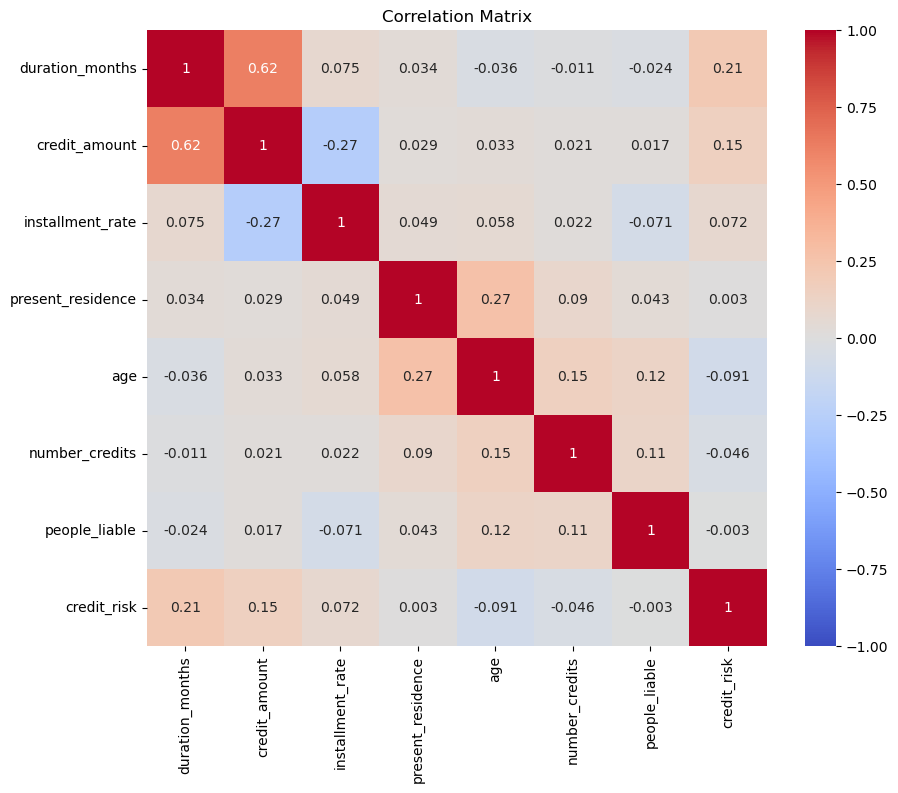

In [31]:
plt.figure(figsize=(10, 8))
sns.heatmap(corr_matrix, annot=True, cmap='coolwarm',vmin=-1, vmax=1)
plt.title('Correlation Matrix')
plt.show()

In [32]:
target_corr = corr_matrix['credit_risk'].drop('credit_risk').abs().sort_values(ascending=False)
target_corr

duration_months      0.214927
credit_amount        0.154739
age                  0.091127
installment_rate     0.072404
number_credits       0.045732
people_liable        0.003015
present_residence    0.002967
Name: credit_risk, dtype: float64

In [33]:
target_corr.head(3)

duration_months    0.214927
credit_amount      0.154739
age                0.091127
Name: credit_risk, dtype: float64

The three numeric features with the strongest absolute correlation with the target are shown above. Correlation shows a linear relationship and does not prove that a feature causes credit risk.

# 3) Preprocessing

## Task 3.1 Split train/test

In [34]:
X = df.drop(columns='credit_risk')
y = df['credit_risk']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

print(X_train.shape)
print(y_train.shape)
print(X_test.shape)
print(y_test.shape)

(800, 20)
(800,)
(200, 20)
(200,)


## Task 3.2 Prepare pipeline

Categorical features are encoded with OneHotEncoder. Numeric features are scaled with StandardScaler. The preprocessing is fitted on the training data inside each pipeline.

In [35]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score, confusion_matrix, precision_score, recall_score, f1_score, ConfusionMatrixDisplay

preprocessor = ColumnTransformer(
    transformers=[
        ('numeric', StandardScaler(), numeric_features),
        ('categorical', OneHotEncoder(handle_unknown='ignore'), categorical_features)
    ]
)

# 4) Build 3 Baseline Models

## Task 4.1 Train models

In [36]:
models = {
    'Logistic Regression': LogisticRegression(max_iter=1000, random_state=42),
    'Decision Tree': DecisionTreeClassifier(random_state=42),
    'kNN': KNeighborsClassifier()
}

fitted_models = {}
for name, model in models.items():
    pipeline = Pipeline([
        ('preprocessing', preprocessor),
        ('model', model)
    ])
    pipeline.fit(X_train, y_train)
    fitted_models[name] = pipeline

## Task 4.2 Evaluate models

Class 1 is Bad Risk, so recall measures how many bad-risk clients the model identifies.

In [37]:
model_results = {}
for name, model in fitted_models.items():
    predictions = model.predict(X_test)
    model_results[name] = {
        'Accuracy': accuracy_score(y_test, predictions),
        'Precision': precision_score(y_test, predictions, zero_division=0),
        'Recall (bad class)': recall_score(y_test, predictions, zero_division=0),
        'F1': f1_score(y_test, predictions, zero_division=0),
        'Confusion Matrix': confusion_matrix(y_test, predictions, labels=[0, 1])
    }
    print(name)
    print(f"Accuracy: {model_results[name]['Accuracy']:.3f}")
    print(f"Precision: {model_results[name]['Precision']:.3f}")
    print(f"Recall: {model_results[name]['Recall (bad class)']:.3f}")
    print(f"F1: {model_results[name]['F1']:.3f}")
    print('Confusion matrix:')
    print(model_results[name]['Confusion Matrix'])
    print()

Logistic Regression
Accuracy: 0.780
Precision: 0.667
Recall: 0.533
F1: 0.593
Confusion matrix:
[[124  16]
 [ 28  32]]

Decision Tree
Accuracy: 0.630
Precision: 0.379
Recall: 0.367
F1: 0.373
Confusion matrix:
[[104  36]
 [ 38  22]]

kNN
Accuracy: 0.725
Precision: 0.568
Recall: 0.350
F1: 0.433
Confusion matrix:
[[124  16]
 [ 39  21]]



Approving a bad client is usually worse for the bank because it can lead to an unpaid loan. In this notebook that error is a false negative: the actual class is Bad Risk (1), but the model predicts Good Risk (0). Rejecting a good client is a false positive and can mean lost business.

# 5) Simple Business Threshold

For logistic regression, a higher probability means higher estimated risk. We predict Bad Risk when the probability is at least the selected threshold.

In [38]:
logistic_model = fitted_models['Logistic Regression']
y_probability = logistic_model.predict_proba(X_test)[:, 1]
threshold_results = {}

for threshold in [0.65, 0.50, 0.35]:
    predictions = (y_probability >= threshold).astype(int)
    threshold_results[threshold] = {
        'Confusion Matrix': confusion_matrix(y_test, predictions, labels=[0, 1]),
        'Precision': precision_score(y_test, predictions, zero_division=0),
        'Recall': recall_score(y_test, predictions, zero_division=0),
        'F1': f1_score(y_test, predictions, zero_division=0),
        'Rejected': int(predictions.sum())
    }

threshold_table = pd.DataFrame({
    threshold: {
        'Precision': values['Precision'],
        'Recall (bad class)': values['Recall'],
        'F1': values['F1'],
        'Predicted as bad / rejected': values['Rejected']
    }
    for threshold, values in threshold_results.items()
}).T
threshold_table.index.name = 'Threshold'
threshold_table

,Precision,Recall (bad class),F1,Predicted as bad / rejected
Threshold,,,,
0.65,0.758621,0.366667,0.494382,29.0
0.50,0.666667,0.533333,0.592593,48.0
0.35,0.597403,0.766667,0.671533,77.0


In [39]:
for threshold, values in threshold_results.items():
    print(f"Threshold = {threshold:.2f}")
    print(values['Confusion Matrix'])
    print()

Threshold = 0.65
[[133   7]
 [ 38  22]]

Threshold = 0.50
[[124  16]
 [ 28  32]]

Threshold = 0.35
[[109  31]
 [ 14  46]]



When the threshold is lowered, more applications are classified as Bad Risk and rejected. At 0.35, the model rejects 77 clients and identifies 46 of 60 bad-risk clients. At 0.50, it rejects 48 clients and identifies 32 bad-risk clients. At 0.65, it rejects 29 clients and identifies 22 bad-risk clients.

I recommend 0.35 if the bank's main goal is to reduce bad clients approved: it leaves 14 bad clients approved, compared with 28 at 0.50 and 38 at 0.65. The trade-off is that 31 good clients are rejected at 0.35, compared with 16 at 0.50 and 7 at 0.65. A Head of Risk should confirm that the reduced credit losses are worth the additional rejected good clients.

# 6) Production-Oriented Task: Manual Review Queue

## Task 6.1 Create decision zones using probability

In [40]:
decision_zone = np.select(
    [y_probability < 0.20, y_probability <= 0.50],
    ['Auto-approve', 'Manual review'],
    default='Auto-reject'
)
zone_counts = pd.Series(decision_zone, name='Decision zone').value_counts().reindex(
    ['Auto-approve', 'Manual review', 'Auto-reject'], fill_value=0
)
zone_counts

Decision zone
Auto-approve     91
Manual review    61
Auto-reject      48
Name: count, dtype: int64

Applications with low estimated risk can be approved automatically, and high-risk applications can be rejected automatically. Only applications in the middle range go to a person for review. This saves review time while giving uncertain cases extra attention.

# 7) Business Demonstration

## Business Demo: Loan Approval Risk Model

In [41]:
best_model_name = max(model_results, key=lambda name: model_results[name]['F1'])
best_model_metrics = model_results[best_model_name]
comparison = pd.DataFrame({
    name: {
        'Accuracy': values['Accuracy'],
        'Recall (bad class)': values['Recall (bad class)'],
        'F1': values['F1']
    }
    for name, values in model_results.items()
}).T
comparison['Comment'] = [
    'Finds a balance between precision and recall.' if name == best_model_name else
    'Baseline result on the test set.'
    for name in comparison.index
]
comparison

,Accuracy,Recall (bad class),F1,Comment
Logistic Regression,0.780,0.533333,0.592593,Finds a balance between precision and recall.
Decision Tree,0.630,0.366667,0.372881,Baseline result on the test set.
kNN,0.725,0.350000,0.432990,Baseline result on the test set.


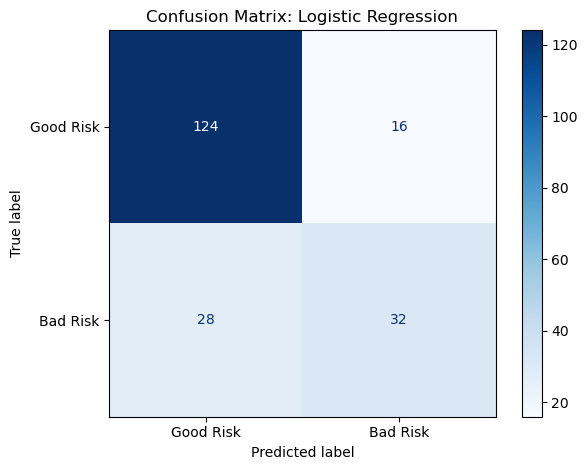

In [42]:
ConfusionMatrixDisplay(
    confusion_matrix=best_model_metrics['Confusion Matrix'],
    display_labels=['Good Risk', 'Bad Risk']
).plot(cmap='Blues', values_format='d')
plt.title(f'Confusion Matrix: {best_model_name}')
plt.tight_layout()
plt.show()

In [43]:
zone_order = ['Auto-approve', 'Manual review', 'Auto-reject']
applicants = []
for zone in zone_order:
    zone_indexes = np.flatnonzero(decision_zone == zone)
    if len(zone_indexes) > 0:
        chosen_index = zone_indexes[np.argsort(y_probability[zone_indexes])[len(zone_indexes) // 2]]
        probability = y_probability[chosen_index]
        if zone == 'Auto-approve':
            explanation = 'The estimated risk is low, so this application can be approved automatically.'
        elif zone == 'Manual review':
            explanation = 'The result is uncertain, so a specialist should check the application before deciding.'
        else:
            explanation = 'The estimated risk is high, so the application is rejected automatically.'
        applicants.append({
            'Applicant': f'Test row {X_test.index[chosen_index]}',
            'Age': X_test.iloc[chosen_index]['age'],
            'Loan duration (months)': X_test.iloc[chosen_index]['duration_months'],
            'Credit amount': X_test.iloc[chosen_index]['credit_amount'],
            'Bad risk probability': probability,
            'Decision zone': zone,
            'Explanation': explanation
        })

applicant_examples = pd.DataFrame(applicants)
applicant_examples['Bad risk probability'] = applicant_examples['Bad risk probability'].map(lambda value: f'{value:.1%}')
applicant_examples

,Applicant,Age,Loan duration (months),Credit amount,Bad risk probability,Decision zone,Explanation
0,Test row 412,42,12,2292,9.1%,Auto-approve,"The estimated risk is low, so this application..."
1,Test row 804,24,12,7472,34.2%,Manual review,"The result is uncertain, so a specialist shoul..."
2,Test row 353,28,12,6199,68.3%,Auto-reject,"The estimated risk is high, so the application..."


The German Credit dataset contains information about 1,000 loan applicants and labels each one as good or bad credit risk. The goal is to identify applicants who may fail to repay a loan. Of the three baseline models, Logistic Regression has the highest F1 score: 0.593, with 0.780 accuracy and 0.533 recall for bad-risk clients.

I recommend threshold 0.35 when reducing bad clients approved is the main priority. It identifies 46 of 60 bad clients, while 31 good clients are rejected. The manual review queue auto-approves 91 cases below 0.20, sends 61 cases from 0.20 to 0.50 for review, and auto-rejects 48 cases above 0.50. The examples below show how these decisions can be explained in business terms.